In [1]:
from pathlib import Path

project_dir = Path.home() / "Customer-Churn-Revenue-Analytics"
data_path = project_dir / "data" / "raw" / "Telco-Customer-Churn.csv"

print("Project folder exists:", project_dir.exists())
print("Dataset exists:", data_path.exists())
print("Dataset path:", data_path)


Project folder exists: True
Dataset exists: True
Dataset path: C:\Users\saire\Customer-Churn-Revenue-Analytics\data\raw\Telco-Customer-Churn.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [3]:
df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Number of rows: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043

In [5]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
# Check for duplicate rows
duplicate_rows = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)

# Check for duplicate customer IDs
duplicate_customer_ids = df["customerID"].duplicated().sum()

print("Number of duplicate customer IDs:", duplicate_customer_ids)

Number of duplicate rows: 0
Number of duplicate customer IDs: 0


In [7]:
# Check for blank or whitespace-only values
blank_values = (
    df.select_dtypes(include="object")
      .apply(lambda column: column.astype("string").str.strip().eq("").sum())
)

print("Blank values in each column:")
print(blank_values[blank_values > 0])

Blank values in each column:
TotalCharges    11
dtype: int64


C:\Users\saire\AppData\Local\Temp\ipykernel_31536\3813357016.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object")


In [8]:
# Inspect the TotalCharges column
print("TotalCharges data type:", df["TotalCharges"].dtype)

print("\nFirst 15 TotalCharges values:")
print(df["TotalCharges"].head(15).to_list())

print("\nNon-numeric TotalCharges values:")
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"].astype("string").str.strip(),
    errors="coerce"
)

print("Values converted to missing:", total_charges_numeric.isna().sum())

TotalCharges data type: str

First 15 TotalCharges values:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95', '587.45', '326.8', '5681.1', '5036.3', '2686.05']

Non-numeric TotalCharges values:
Values converted to missing: 11


In [9]:
# Create a working copy of the original dataset
df_clean = df.copy()

# Remove leading and trailing spaces from text columns
text_columns = df_clean.select_dtypes(include=["object"]).columns

for column in text_columns:
    df_clean[column] = df_clean[column].str.strip()

# Convert TotalCharges into a numeric column
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Display the data type and missing-value count
print("TotalCharges data type:", df_clean["TotalCharges"].dtype)

print(
    "Missing TotalCharges values:",
    df_clean["TotalCharges"].isna().sum()
)

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

TotalCharges data type: float64
Missing TotalCharges values: 11
Original dataset shape: (7043, 21)
Working dataset shape: (7043, 21)


C:\Users\saire\AppData\Local\Temp\ipykernel_31536\1279138661.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df_clean.select_dtypes(include=["object"]).columns


In [10]:
# Inspect records with missing TotalCharges
missing_total_charges = df_clean[
    df_clean["TotalCharges"].isna()
]

display(
    missing_total_charges[
        ["customerID", "tenure", "MonthlyCharges",
         "TotalCharges", "Churn"]
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [11]:
print("Tenure values for affected customers:")
print(missing_total_charges["tenure"].value_counts())

print("\nMinimum tenure in affected records:")
print(missing_total_charges["tenure"].min())

print("\nMaximum tenure in affected records:")
print(missing_total_charges["tenure"].max())

Tenure values for affected customers:
tenure
0    11
Name: count, dtype: int64

Minimum tenure in affected records:
0

Maximum tenure in affected records:
0


In [12]:
print("Dataset dimensions:", df_clean.shape)

print("\nData types:")
print(df_clean.dtypes)

print("\nMissing values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nDuplicate rows:", df_clean.duplicated().sum())

print(
    "Duplicate customer IDs:",
    df_clean["customerID"].duplicated().sum()
)

Dataset dimensions: (7043, 21)

Data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

Missing values:
TotalCharges    11
dtype: int64

Duplicate rows: 0
Duplicate customer IDs: 0


In [13]:
# Fill TotalCharges with 0 for customers with zero tenure
df_clean.loc[
    (df_clean["tenure"] == 0) &
    (df_clean["TotalCharges"].isna()),
    "TotalCharges"
] = 0

# Verify the changes
print(
    "Missing TotalCharges after cleaning:",
    df_clean["TotalCharges"].isna().sum()
)

print(
    "Customers with zero tenure:",
    (df_clean["tenure"] == 0).sum()
)

print(
    "Customers with zero tenure and zero TotalCharges:",
    (
        (df_clean["tenure"] == 0) &
        (df_clean["TotalCharges"] == 0)
    ).sum()
)

print("Final dataset shape:", df_clean.shape)

Missing TotalCharges after cleaning: 0
Customers with zero tenure: 11
Customers with zero tenure and zero TotalCharges: 11
Final dataset shape: (7043, 21)


In [14]:
# Final data-quality report
print("========== FINAL DATA QUALITY REPORT ==========")

print("\nDataset dimensions:")
print(df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nDuplicate customer IDs:")
print(df_clean["customerID"].duplicated().sum())

print("\nData types:")
print(df_clean.dtypes)

print("\nFirst five cleaned records:")
display(df_clean.head())

========== FINAL DATA QUALITY REPORT ==========

Dataset dimensions:
(7043, 21)

Missing values:
0

Duplicate rows:
0

Duplicate customer IDs:
0

Data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

First five cleaned records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [15]:
from pathlib import Path

processed_dir = project_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

cleaned_file = processed_dir / "telco_customer_churn_cleaned.csv"

df_clean.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")
print("Location:", cleaned_file)
print("Records saved:", len(df_clean))

Cleaned dataset saved successfully!
Location: C:\Users\saire\Customer-Churn-Revenue-Analytics\data\processed\telco_customer_churn_cleaned.csv
Records saved: 7043


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visual style
sns.set_theme(style="whitegrid")

# Load the cleaned dataset
df_clean = pd.read_csv(cleaned_file)

print("Cleaned dataset loaded successfully!")
print("Dataset shape:", df_clean.shape)

# Check the churn categories
print("\nCustomer churn categories:")
print(df_clean["Churn"].value_counts())

print("\nChurn percentages:")
print(
    (df_clean["Churn"].value_counts(normalize=True) * 100)
    .round(2)
)

NameError: name 'cleaned_file' is not defined

In [2]:
# Calculate key customer and revenue metrics

total_customers = len(df_clean)

churned_customers = (df_clean["Churn"] == "Yes").sum()

retained_customers = (df_clean["Churn"] == "No").sum()

churn_rate = (churned_customers / total_customers) * 100

retention_rate = (retained_customers / total_customers) * 100

average_monthly_charges = df_clean["MonthlyCharges"].mean()

total_monthly_charges = df_clean["MonthlyCharges"].sum()

churned_customer_monthly_charges = df_clean.loc[
    df_clean["Churn"] == "Yes",
    "MonthlyCharges"
].sum()

print("========== CUSTOMER CHURN KPIs ==========")

print(f"Total Customers: {total_customers:,}")
print(f"Churned Customers: {churned_customers:,}")
print(f"Retained Customers: {retained_customers:,}")
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")
print(f"Average Monthly Charge: ${average_monthly_charges:,.2f}")
print(f"Total Customer Monthly Charges: ${total_monthly_charges:,.2f}")
print(
    "Monthly Charges Associated with Churned Customers: "
    f"${churned_customer_monthly_charges:,.2f}"
)

NameError: name 'df_clean' is not defined

In [3]:
from pathlib import Path

project_dir = Path.home() / "Customer-Churn-Revenue-Analytics"

cleaned_file = (
    project_dir
    / "data"
    / "processed"
    / "telco_customer_churn_cleaned.csv"
)

print("Project folder exists:", project_dir.exists())
print("Cleaned dataset exists:", cleaned_file.exists())
print("Dataset path:", cleaned_file)

Project folder exists: True
Cleaned dataset exists: True
Dataset path: C:\Users\saire\Customer-Churn-Revenue-Analytics\data\processed\telco_customer_churn_cleaned.csv


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df_clean = pd.read_csv(cleaned_file)

print("Cleaned dataset loaded successfully!")
print("Dataset shape:", df_clean.shape)

Cleaned dataset loaded successfully!
Dataset shape: (7043, 21)


In [5]:
print("CUSTOMER CHURN ANALYSIS")

print("\nCustomer counts:")
print(df_clean["Churn"].value_counts())

print("\nCustomer percentages:")
print(
    (df_clean["Churn"].value_counts(normalize=True) * 100).round(2)
)

CUSTOMER CHURN ANALYSIS

Customer counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [6]:
# ==========================================
# STEP 6: KEY BUSINESS PERFORMANCE INDICATORS
# ==========================================

total_customers = len(df_clean)

churned_customers = (df_clean["Churn"] == "Yes").sum()

retained_customers = (df_clean["Churn"] == "No").sum()

churn_rate = (churned_customers / total_customers) * 100

retention_rate = (retained_customers / total_customers) * 100

average_monthly_charges = df_clean["MonthlyCharges"].mean()

total_monthly_charges = df_clean["MonthlyCharges"].sum()

churned_monthly_charges = df_clean.loc[
    df_clean["Churn"] == "Yes",
    "MonthlyCharges"
].sum()

# Display results
print("========== BUSINESS KPI REPORT ==========")

print(f"Total Customers: {total_customers:,}")

print(f"Churned Customers: {churned_customers:,}")

print(f"Retained Customers: {retained_customers:,}")

print(f"Churn Rate: {churn_rate:.2f}%")

print(f"Retention Rate: {retention_rate:.2f}%")

print(
    f"Average Monthly Charges: "
    f"${average_monthly_charges:,.2f}"
)

print(
    f"Total Monthly Charges Across All Customers: "
    f"${total_monthly_charges:,.2f}"
)

print(
    f"Monthly Charges Associated with Churned Customers: "
    f"${churned_monthly_charges:,.2f}"
)

========== BUSINESS KPI REPORT ==========
Total Customers: 7,043
Churned Customers: 1,869
Retained Customers: 5,174
Churn Rate: 26.54%
Retention Rate: 73.46%
Average Monthly Charges: $64.76
Total Monthly Charges Across All Customers: $456,116.60
Monthly Charges Associated with Churned Customers: $139,130.85


In [7]:
# ==========================================
# STEP 7: CHURN BY CONTRACT TYPE
# ==========================================

contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"]
)

contract_churn["Total Customers"] = (
    contract_churn["Yes"] + contract_churn["No"]
)

contract_churn["Churn Rate (%)"] = (
    contract_churn["Yes"]
    / contract_churn["Total Customers"]
    * 100
).round(2)

print("========== CHURN BY CONTRACT TYPE ==========")

display(contract_churn)

========== CHURN BY CONTRACT TYPE ==========


Churn,No,Yes,Total Customers,Churn Rate (%)
Contract,,,,
Month-to-month,2220,1655,3875,42.71
One year,1307,166,1473,11.27
Two year,1647,48,1695,2.83


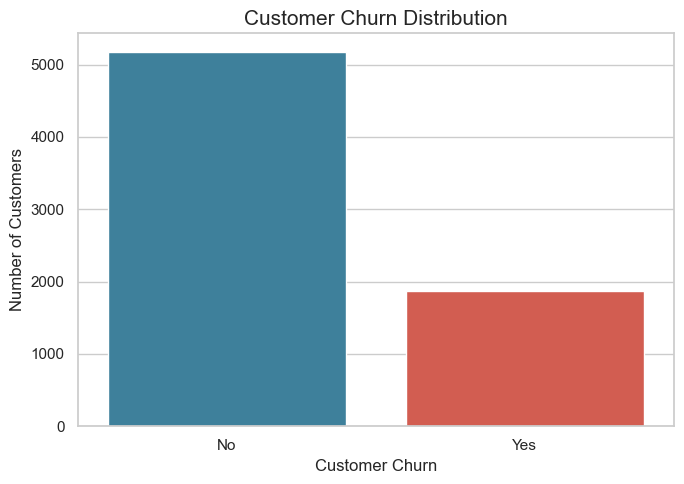

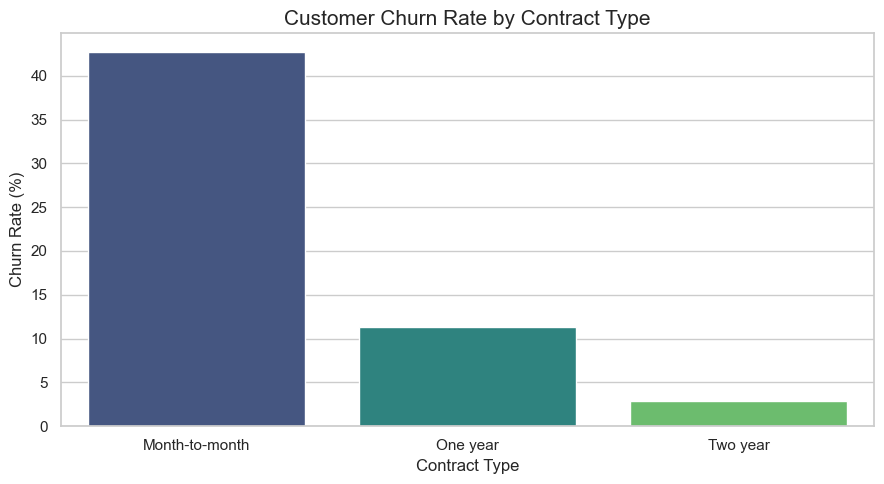

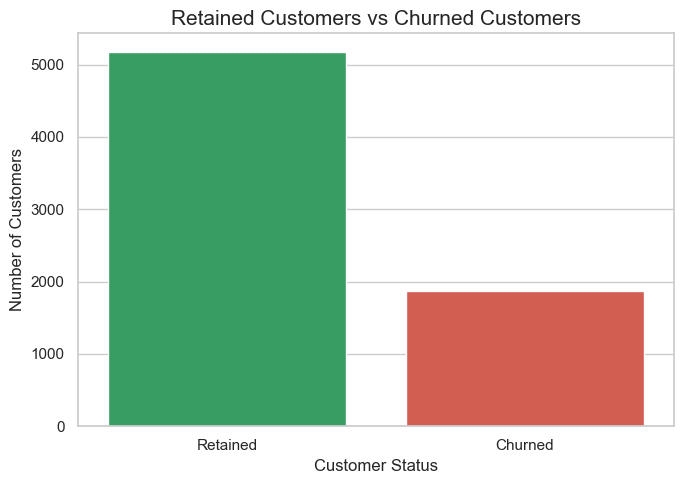

All three visualizations generated successfully!


In [8]:
# ==========================================
# STEP 8: CUSTOMER CHURN VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Chart 1: Customer churn distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    palette=["#2E86AB", "#E74C3C"],
    legend=False
)

plt.title("Customer Churn Distribution", fontsize=15)
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# Chart 2: Churn rate by contract type
contract_plot = contract_churn.reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=contract_plot,
    x="Contract",
    y="Churn Rate (%)",
    hue="Contract",
    palette="viridis",
    legend=False
)

plt.title("Customer Churn Rate by Contract Type", fontsize=15)
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


# Chart 3: Retained versus churned customers
customer_status = pd.DataFrame({
    "Customer Status": ["Retained", "Churned"],
    "Customers": [retained_customers, churned_customers]
})

plt.figure(figsize=(7, 5))

sns.barplot(
    data=customer_status,
    x="Customer Status",
    y="Customers",
    hue="Customer Status",
    palette=["#27AE60", "#E74C3C"],
    legend=False
)

plt.title("Retained Customers vs Churned Customers", fontsize=15)
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("All three visualizations generated successfully!")

CHURN RATE BY TENURE GROUP


,TenureGroup,Churn Rate (%)
0,0-12 months,47.438243
1,13-24 months,28.710938
2,25-48 months,20.388959
3,49-60 months,14.423077
4,61-72 months,6.609808


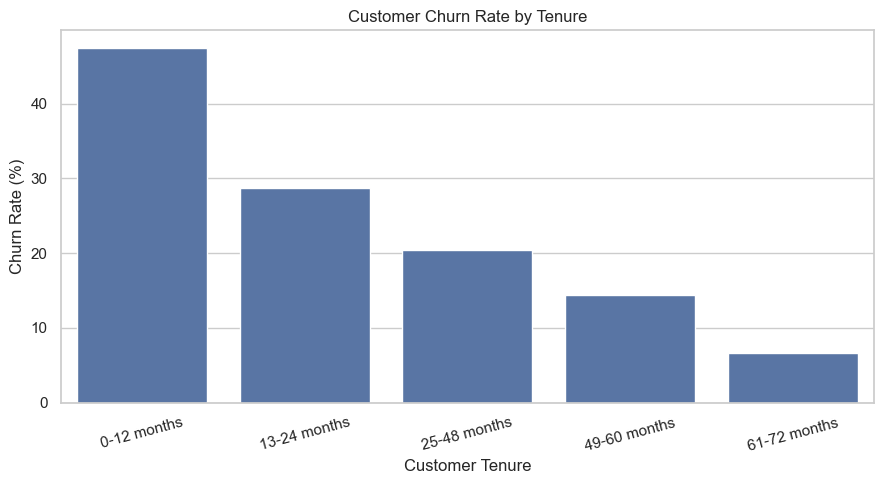

CHURN RATE BY INTERNET SERVICE


,InternetService,Total_Customers,Churned_Customers,Churn Rate (%)
0,DSL,2421,459,18.96
1,Fiber optic,3096,1297,41.89
2,No,1526,113,7.40


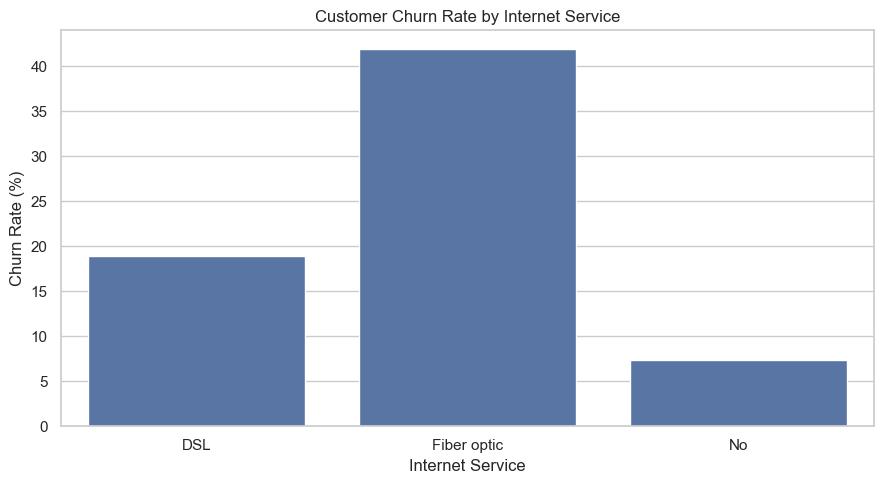

CHURN RATE BY PAYMENT METHOD


,PaymentMethod,Total_Customers,Churned_Customers,Churn Rate (%)
2,Electronic check,2365,1071,45.29
3,Mailed check,1612,308,19.11
0,Bank transfer (automatic),1544,258,16.71
1,Credit card (automatic),1522,232,15.24


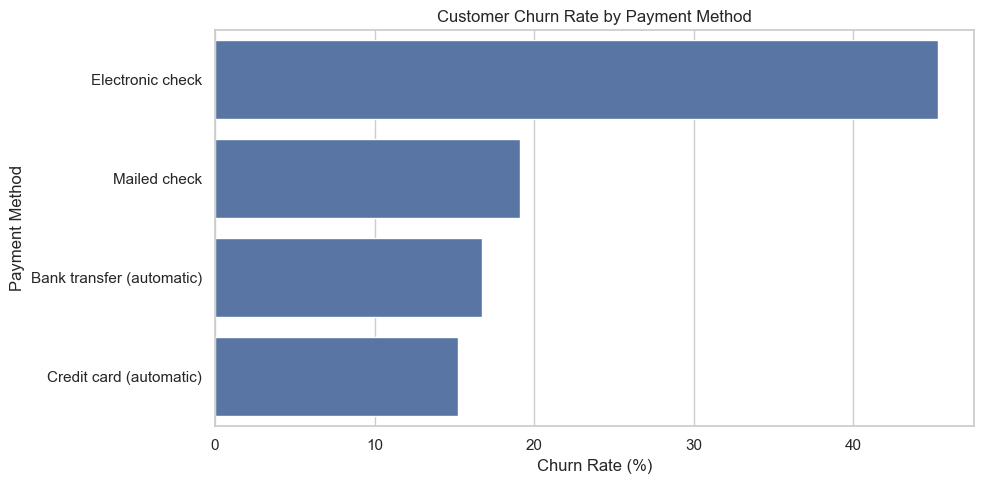

Step 9 completed successfully!


In [9]:
# ==========================================
# STEP 9: CUSTOMER CHURN BY KEY FACTORS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ------------------------------------------
# 1. Churn by tenure group
# ------------------------------------------

df_clean["TenureGroup"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-60 months",
        "61-72 months"
    ]
)

tenure_churn = (
    df_clean.groupby("TenureGroup", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn Rate (%)")
)

print("CHURN RATE BY TENURE GROUP")
display(tenure_churn)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=tenure_churn,
    x="TenureGroup",
    y="Churn Rate (%)"
)
plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# ------------------------------------------
# 2. Churn by internet service
# ------------------------------------------

internet_churn = (
    df_clean.groupby("InternetService", observed=False)
    .agg(
        Total_Customers=("Churn", "size"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
    .reset_index()
)

internet_churn["Churn Rate (%)"] = (
    internet_churn["Churned_Customers"]
    / internet_churn["Total_Customers"]
    * 100
).round(2)

print("CHURN RATE BY INTERNET SERVICE")
display(internet_churn)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=internet_churn,
    x="InternetService",
    y="Churn Rate (%)"
)
plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


# ------------------------------------------
# 3. Churn by payment method
# ------------------------------------------

payment_churn = (
    df_clean.groupby("PaymentMethod", observed=False)
    .agg(
        Total_Customers=("Churn", "size"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
    .reset_index()
)

payment_churn["Churn Rate (%)"] = (
    payment_churn["Churned_Customers"]
    / payment_churn["Total_Customers"]
    * 100
).round(2)

payment_churn = payment_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

print("CHURN RATE BY PAYMENT METHOD")
display(payment_churn)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=payment_churn,
    x="Churn Rate (%)",
    y="PaymentMethod"
)
plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Payment Method")
plt.tight_layout()
plt.show()

print("Step 9 completed successfully!")

========== REVENUE KPI REPORT ==========
Total customers: 7,043
Average monthly charges per customer: $64.76
Total monthly charges across customers: $456,116.60
Monthly charges associated with churned customers: $139,130.85
Monthly charges associated with retained customers: $316,985.75

========== REVENUE BY CONTRACT ==========


,Contract,Customer_Count,Average_Monthly_Charges,Total_Monthly_Charges
0,Month-to-month,3875,66.40,257294.15
1,One year,1473,65.05,95816.60
2,Two year,1695,60.77,103005.85



========== REVENUE BY INTERNET SERVICE ==========


,InternetService,Customer_Count,Average_Monthly_Charges,Total_Monthly_Charges
0,DSL,2421,58.10,140665.35
1,Fiber optic,3096,91.50,283284.40
2,No,1526,21.08,32166.85



========== REVENUE BY CHURN STATUS ==========


,Churn,Customer_Count,Average_Monthly_Charges,Total_Monthly_Charges
0,No,5174,61.27,316985.75
1,Yes,1869,74.44,139130.85


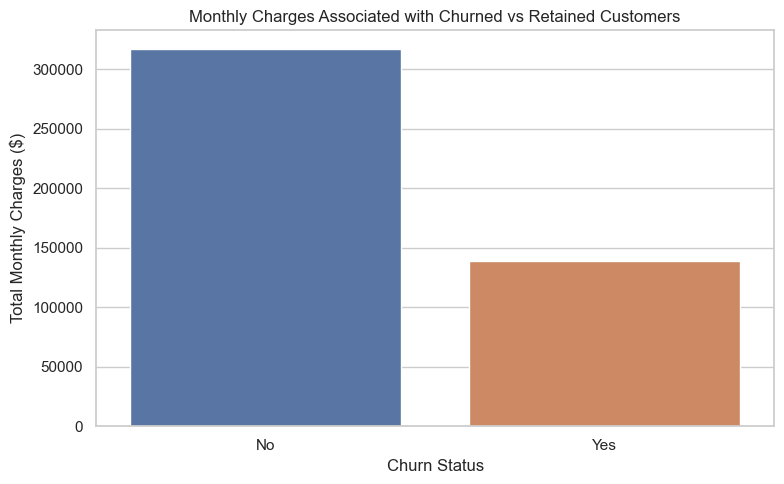

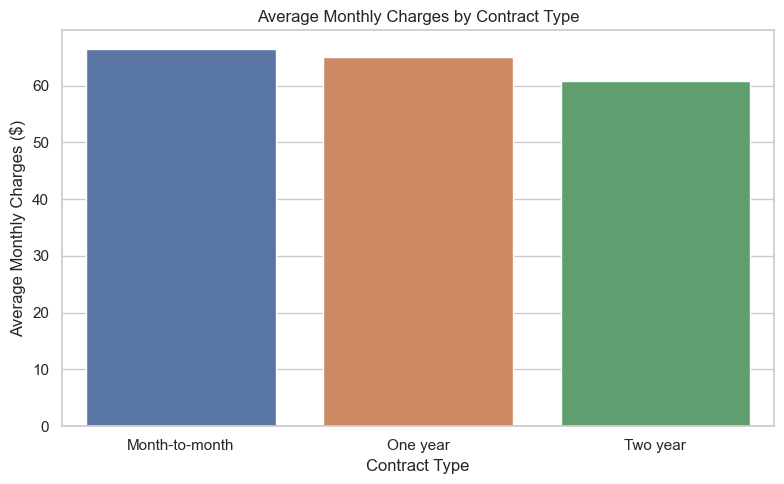

Step 10 completed successfully!


In [10]:
# ==========================================
# STEP 10: REVENUE ANALYSIS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Ensure charge columns are numeric
df_clean["MonthlyCharges"] = pd.to_numeric(
    df_clean["MonthlyCharges"], errors="coerce"
)

df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"], errors="coerce"
)

# ------------------------------------------
# 1. Overall revenue-related KPIs
# ------------------------------------------

total_customers = len(df_clean)

average_monthly_charges = df_clean["MonthlyCharges"].mean()

total_monthly_charges = df_clean["MonthlyCharges"].sum()

churned_monthly_charges = df_clean.loc[
    df_clean["Churn"] == "Yes", "MonthlyCharges"
].sum()

retained_monthly_charges = df_clean.loc[
    df_clean["Churn"] == "No", "MonthlyCharges"
].sum()

print("========== REVENUE KPI REPORT ==========")
print(f"Total customers: {total_customers:,}")
print(f"Average monthly charges per customer: ${average_monthly_charges:,.2f}")
print(f"Total monthly charges across customers: ${total_monthly_charges:,.2f}")
print(f"Monthly charges associated with churned customers: ${churned_monthly_charges:,.2f}")
print(f"Monthly charges associated with retained customers: ${retained_monthly_charges:,.2f}")


# ------------------------------------------
# 2. Average monthly charges by contract
# ------------------------------------------

contract_revenue = (
    df_clean.groupby("Contract", observed=False)
    .agg(
        Customer_Count=("customerID", "count"),
        Average_Monthly_Charges=("MonthlyCharges", "mean"),
        Total_Monthly_Charges=("MonthlyCharges", "sum")
    )
    .reset_index()
)

contract_revenue["Average_Monthly_Charges"] = (
    contract_revenue["Average_Monthly_Charges"].round(2)
)

contract_revenue["Total_Monthly_Charges"] = (
    contract_revenue["Total_Monthly_Charges"].round(2)
)

print("\n========== REVENUE BY CONTRACT ==========")
display(contract_revenue)


# ------------------------------------------
# 3. Monthly charges by internet service
# ------------------------------------------

internet_revenue = (
    df_clean.groupby("InternetService", observed=False)
    .agg(
        Customer_Count=("customerID", "count"),
        Average_Monthly_Charges=("MonthlyCharges", "mean"),
        Total_Monthly_Charges=("MonthlyCharges", "sum")
    )
    .reset_index()
)

internet_revenue["Average_Monthly_Charges"] = (
    internet_revenue["Average_Monthly_Charges"].round(2)
)

internet_revenue["Total_Monthly_Charges"] = (
    internet_revenue["Total_Monthly_Charges"].round(2)
)

print("\n========== REVENUE BY INTERNET SERVICE ==========")
display(internet_revenue)


# ------------------------------------------
# 4. Compare charges by churn status
# ------------------------------------------

churn_revenue = (
    df_clean.groupby("Churn", observed=False)
    .agg(
        Customer_Count=("customerID", "count"),
        Average_Monthly_Charges=("MonthlyCharges", "mean"),
        Total_Monthly_Charges=("MonthlyCharges", "sum")
    )
    .reset_index()
)

churn_revenue["Average_Monthly_Charges"] = (
    churn_revenue["Average_Monthly_Charges"].round(2)
)

churn_revenue["Total_Monthly_Charges"] = (
    churn_revenue["Total_Monthly_Charges"].round(2)
)

print("\n========== REVENUE BY CHURN STATUS ==========")
display(churn_revenue)


# ------------------------------------------
# 5. Visualize monthly charges by churn status
# ------------------------------------------

plt.figure(figsize=(8, 5))

sns.barplot(
    data=churn_revenue,
    x="Churn",
    y="Total_Monthly_Charges",
    hue="Churn",
    legend=False
)

plt.title("Monthly Charges Associated with Churned vs Retained Customers")
plt.xlabel("Churn Status")
plt.ylabel("Total Monthly Charges ($)")
plt.tight_layout()
plt.show()


# ------------------------------------------
# 6. Visualize average monthly charges by contract
# ------------------------------------------

plt.figure(figsize=(8, 5))

sns.barplot(
    data=contract_revenue,
    x="Contract",
    y="Average_Monthly_Charges",
    hue="Contract",
    legend=False
)

plt.title("Average Monthly Charges by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Average Monthly Charges ($)")
plt.tight_layout()
plt.show()


print("Step 10 completed successfully!")

In [11]:
# STEP 11A: EXPORT CLEANED DATA FOR MYSQL

from pathlib import Path

project_dir = Path.home() / "Customer-Churn-Revenue-Analytics"

processed_dir = project_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

mysql_file = processed_dir / "telco_customer_churn_mysql.csv"

# Create a separate export copy
df_sql = df_clean.copy()

# Remove the analysis-only column if it exists
if "TenureGroup" in df_sql.columns:
    df_sql.drop(columns=["TenureGroup"], inplace=True)

# Export to CSV
df_sql.to_csv(mysql_file, index=False)

print("SQL export created successfully!")
print("File location:", mysql_file)
print("Number of records:", len(df_sql))
print("Number of columns:", len(df_sql.columns))

SQL export created successfully!
File location: C:\Users\saire\Customer-Churn-Revenue-Analytics\data\processed\telco_customer_churn_mysql.csv
Number of records: 7043
Number of columns: 21


In [12]:
USE customer_churn_db;

CREATE TABLE IF NOT EXISTS customer_churn (
    customerID VARCHAR(20) PRIMARY KEY,
    gender VARCHAR(10),
    SeniorCitizen INT,
    Partner VARCHAR(10),
    Dependents VARCHAR(10),
    tenure INT,
    PhoneService VARCHAR(25),
    MultipleLines VARCHAR(30),
    InternetService VARCHAR(30),
    OnlineSecurity VARCHAR(30),
    OnlineBackup VARCHAR(30),
    DeviceProtection VARCHAR(30),
    TechSupport VARCHAR(30),
    StreamingTV VARCHAR(30),
    StreamingMovies VARCHAR(30),
    Contract VARCHAR(30),
    PaperlessBilling VARCHAR(10),
    PaymentMethod VARCHAR(50),
    MonthlyCharges DECIMAL(10,2),
    TotalCharges DECIMAL(10,2),
    Churn VARCHAR(10)
);

SyntaxError: invalid syntax (3696024182.py, line 1)